# Laboratorium: standaryzacja, SGD i mini-batch

**Podstawy AI**

Na poprzednich zajęciach Adaline uczył się pełnym spadkiem gradientu: jeden krok na epokę, policzony z całego zbioru. Działało, ale zakres dobrych $\eta$ był wąski, a przy małym $\eta$ trzeba było setek epok. Dziś trzy narzędzia:

1. **standaryzacja** cech — jedno $\eta$ pasuje do wszystkich wag,
2. **stochastyczny spadek gradientu (SGD)** — krok po każdym przykładzie,
3. **mini-batch** — krok z porcji $B$ przykładów; tak uczy się praktycznie każda sieć neuronowa.

Najwięcej czasu poświęcimy mini-batchowi: szumowi gradientu, doborowi $\eta$ razem z $B$ i czasowi obliczeń.

**Jak pracujemy:** komórki `# TODO` uzupełniasz sam; w eksperymentach: **przewiduję → uruchamiam → wyjaśniam**. Na koniec notebook na GitHub.

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_breast_cancer

np.set_printoptions(precision=4, suppress=True)

# Iris: setosa (0) i versicolor (1), cechy: długość działki i płatka [cm]
iris = load_iris()
X = iris.data[:100][:, [0, 2]]
y = (iris.target[:100] == 1).astype(float)

# Adaline z poprzednich zajęć (pełny spadek gradientu) — gotowy
class AdalineGD:
    def __init__(self, eta=0.01, n_iter=50, random_state=1):
        self.eta, self.n_iter, self.random_state = eta, n_iter, random_state

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        self.losses_ = []
        for _ in range(self.n_iter):
            errors = y - self.net_input(X)
            self.w_ += self.eta * 2.0 * X.T @ errors / X.shape[0]
            self.b_ += self.eta * 2.0 * errors.mean()
            self.losses_.append((errors ** 2).mean())
        return self

    def net_input(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.5, 1, 0)

# Część 1: standaryzacja

Każdą cechę $j$ przesuwamy i skalujemy: $\quad x'_j = \dfrac{x_j - \mu_j}{\sigma_j}$, gdzie $\mu_j$ to średnia, a $\sigma_j$ odchylenie standardowe cechy.

### Zadanie 1
Utwórz `X_std`: standaryzowaną kopię `X` (operacja na kolumnach: `X.mean(axis=0)`, `X.std(axis=0)`).

In [3]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)

print("średnie:", X_std.mean(axis=0), " odchylenia:", X_std.std(axis=0))

średnie: [-0. -0.]  odchylenia: [1. 1.]


### Zadanie 2: granica stabilności po standaryzacji
Na surowych danych Iris największe działające $\eta$ to ok. 0.025. Ucz `AdalineGD` na `X_std` przez 100 epok dla $\eta \in \{0.1,\ 0.3,\ 0.5,\ 0.55,\ 0.56,\ 0.6\}$ i wypisz MSE w ostatniej epoce oraz trafność.

**Przewiduję:** o ile wzrośnie granica stabilności?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**
Granica stabilności powinna wzrosnąć kilkunastu lub kilkudziesięco-krotnie (mniej niż 100).

In [4]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.1, 0.3, 0.5, 0.55, 0.56, 0.6]:
        ada = AdalineGD(eta=eta, n_iter=100).fit(X_std, y)
        traf = (ada.predict(X_std) == y).mean()
        print(f"eta = {eta:<4} | MSE: {ada.losses_[-1]:.4f} | trafność: {traf:.2%}")

eta = 0.1  | MSE: 0.0122 | trafność: 100.00%
eta = 0.3  | MSE: 0.0122 | trafność: 100.00%
eta = 0.5  | MSE: 0.0122 | trafność: 100.00%
eta = 0.55 | MSE: 0.0667 | trafność: 100.00%
eta = 0.56 | MSE: 65.7039 | trafność: 4.00%
eta = 0.6  | MSE: 13914822485960.4883 | trafność: 4.00%


### Dlaczego to pomaga: poziomice straty

Funkcja poniżej rysuje **prawdziwe** poziomice straty Iris w funkcji wagi działki $w_1$ i biasu $b$ (druga waga ustalona na końcowej wartości) oraz ścieżkę spadku gradientu. Uruchom ją dla danych surowych i standaryzowanych.

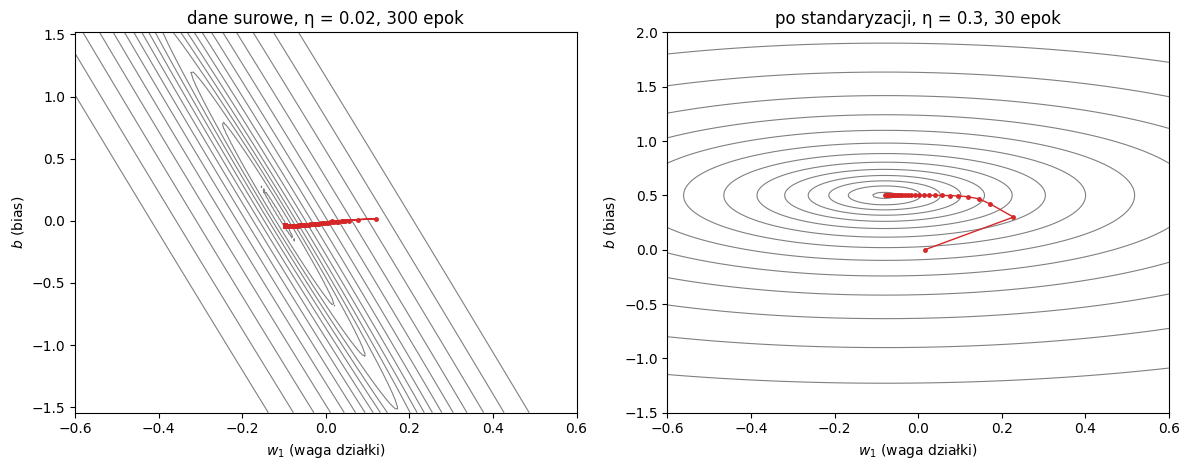

In [5]:
def rysuj_poziomice(Xd, eta, n_epok, ax, tytul):
    # spadek gradientu, zapamiętujemy (w1, b) po każdej epoce
    w, b = np.random.RandomState(1).normal(0, 0.01, 2), 0.0
    sciezka = [(w[0], b)]
    for _ in range(n_epok):
        e = y - (Xd @ w + b)
        w = w + eta * 2 * Xd.T @ e / len(y); b += eta * 2 * e.mean()
        sciezka.append((w[0], b))
    s = np.array(sciezka)
    # poziomice MSE w funkcji (w1, b) przy końcowym w2
    w1_zakres = np.linspace(-0.6, 0.6, 200)
    b_zakres = np.linspace(min(-0.5, s[:, 1].min() - 1.5), max(1.0, s[:, 1].max() + 1.5), 200)
    W1, Bb = np.meshgrid(w1_zakres, b_zakres)
    Z = ((y[:, None, None] - (Xd[:, 0, None, None] * W1 + Xd[:, 1, None, None] * w[1] + Bb)) ** 2).mean(axis=0)
    ax.contour(W1, Bb, Z, levels=np.geomspace(0.013, 3, 14), colors="gray", linewidths=0.8)
    ax.plot(s[:, 0], s[:, 1], "-o", color="tab:red", ms=2.5, lw=1)
    ax.set_title(tytul); ax.set_xlabel("$w_1$ (waga działki)"); ax.set_ylabel("$b$ (bias)")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
rysuj_poziomice(X, eta=0.02, n_epok=300, ax=axs[0], tytul="dane surowe, η = 0.02, 300 epok")
rysuj_poziomice(X_std, eta=0.3, n_epok=30, ax=axs[1], tytul="po standaryzacji, η = 0.3, 30 epok")
plt.tight_layout(); plt.show()

**Pytanie 1.** (a) O ile wzrosła granica stabilności po standaryzacji? (b) Jak wygląda dolina straty dla danych surowych i co robi w niej ścieżka spadku gradientu? (c) Skąd bierze się ukośna dolina? Wskazówka: średnia długość działki to ok. 5.5 cm. Co się dzieje z $z = w_1 x_1 + \dots + b$, gdy zwiększymy $w_1$ o $0.1$, a zmniejszymy $b$ o $0.55$?

✍️ **Twoja odpowiedź:**

(a) Granica stabilności po standaryzacji wzrosła ponad 20 krotnie z ok 0.025 do 0.55. Dla wyższych η rośnie ona do nieskończoności.

(b) Dla danych surowych dolina funkcji straty jest bardzo wąska, wydłużona i mocno nachylona (ukośna). Przy większym η ścieżka spadku gradientu odbija się od stromych ścian doliny (oscyluje w poprzek), a przy małym η bardzo powoli pełznie wzdłuż jej dna.

(c)
Średnia wartość cechy x1 jest niezerowa (ok. 5.5), więc parametry w1 i b są ze sobą silnie skorelowane w równaniu na z. Zwiększenie w o 0.1 podnosi z o średnio 0.55. Zmniejszenie b o 0.55 kompensuje tę zmianę, więc funkcja z ma taką samą wartość.

### Breast Cancer: 30 cech w bardzo różnych skalach

Zbiór Breast Cancer: 569 guzów, 30 cech z obrazów komórek, klasa 1 = łagodny, 0 = złośliwy.

In [6]:
bc = load_breast_cancer()
Xb, yb = bc.data, bc.target.astype(float)
print("Kształt:", Xb.shape, " klasy:", np.bincount(yb.astype(int)))
for j in [0, 3, 4, 9, 23]:
    print(f"  {bc.feature_names[j]:<22} od {Xb[:, j].min():9.4f} do {Xb[:, j].max():9.4f}")

Kształt: (569, 30)  klasy: [212 357]
  mean radius            od    6.9810 do   28.1100
  mean area              od  143.5000 do 2501.0000
  mean smoothness        od    0.0526 do    0.1634
  mean fractal dimension od    0.0500 do    0.0974
  worst area             od  185.2000 do 4254.0000


### Zadanie 3
1. Utwórz `Xb_std`.
2. Ucz `AdalineGD` przez 100 epok na **surowych** `Xb` dla $\eta \in \{10^{-7},\ 5\cdot10^{-7},\ 10^{-6}\}$ i na **standaryzowanych** `Xb_std` dla $\eta \in \{0.01,\ 0.07,\ 0.08\}$. Wypisz MSE i trafność.

In [7]:
Xb_std = (Xb - Xb.mean(axis=0)) / Xb.std(axis=0)

with np.errstate(over="ignore", invalid="ignore"):
    print("--- Surowe Xb ---")
    for eta in [1e-7, 5e-7, 1e-6]:
        ada = AdalineGD(eta=eta, n_iter=100).fit(Xb, yb)
        traf = (ada.predict(Xb) == yb).mean()
        print(f"eta = {eta:<7} | MSE: {ada.losses_[-1]:.4f} | trafność: {traf:.2%}")

    print("\n--- Standaryzowane Xb_std ---")
    for eta in [0.01, 0.07, 0.08]:
        ada = AdalineGD(eta=eta, n_iter=100).fit(Xb_std, yb)
        traf = (ada.predict(Xb_std) == yb).mean()
        print(f"eta = {eta:<7} | MSE: {ada.losses_[-1]:.4f} | trafność: {traf:.2%}")

--- Surowe Xb ---
eta = 1e-07   | MSE: 1.5477 | trafność: 18.45%
eta = 5e-07   | MSE: 0.4443 | trafność: 21.44%
eta = 1e-06   | MSE: 40317025157071209443178990527659505842951822535863716486538483326368350208.0000 | trafność: 37.26%

--- Standaryzowane Xb_std ---
eta = 0.01    | MSE: 0.0709 | trafność: 97.36%
eta = 0.07    | MSE: 0.0568 | trafność: 96.49%
eta = 0.08    | MSE: 1792130259.0934 | trafność: 8.44%


**Pytanie 2.** Ile wynosi granica stabilności na danych surowych, a ile po standaryzacji? Dlaczego na Breast Cancer różnica jest dużo większa niż na Iris?

✍️ **Twoja odpowiedź:**

Granica stabilności na surowych danych 5*10^-7, potem algorytm się rozbiega. Po standaryzacji natomiast zaczyna się rozbiegać dla 0.8, ponieważ w zbiorze Breast Cancer rozpiętość skal między wartościami cech jest dużo większa. Kwadraty dużych wartości w gradiencie zmuszają więc do małego η.

# Część 2: SGD i jedna klasa na wszystko

Mini-batch: krok liczymy z porcji (*batch*) $B$ przykładów:

$$w_j := w_j + \eta \cdot \frac{2}{|\text{batch}|}\sum_{i \in \text{batch}} \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad b := b + \eta \cdot \frac{2}{|\text{batch}|}\sum_{i \in \text{batch}} \left(y^{(i)} - z^{(i)}\right)$$

- $B = 1$: **SGD** (krok po każdym przykładzie),
- $B = n$: **pełny spadek gradientu** (jak `AdalineGD`),
- pomiędzy: **mini-batch**.

### Zadanie 4 — uzupełnij `fit`
W pętli po batchach brakuje **pięciu linijek**:
1. `batch` — indeksy przykładów w tym batchu: kolejne $B$ elementów z `idx`, od pozycji `start`,
2. `Xb, yb` — cechy i etykiety tych przykładów,
3. `errors` — błędy $y - z$ dla batcha,
4. i 5. aktualizacja wag i biasu (dzielimy przez `len(batch)`, bo ostatni batch może być mniejszy niż $B$).

In [8]:
class AdalineMB:
    """Adaline uczony spadkiem gradientu na mini-batchach.

    batch_size=1 -> SGD,  batch_size=len(y) -> pełny spadek gradientu.
    Atrybuty po uczeniu: w_, b_, losses_ (MSE na całym zbiorze po każdej epoce), n_krokow_.
    Przy zapisuj_kroki=True także losses_kroki_ (MSE po każdym kroku).
    """

    def __init__(self, eta=0.01, n_iter=10, batch_size=32, shuffle=True, random_state=1, zapisuj_kroki=False):
        self.eta = eta
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.random_state = random_state
        self.zapisuj_kroki = zapisuj_kroki

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        self.losses_, self.losses_kroki_, self.n_krokow_ = [], [], 0
        n = len(y)
        for _ in range(self.n_iter):
            idx = rgen.permutation(n) if self.shuffle else np.arange(n)   # tasowanie przed każdą epoką
            for start in range(0, n, self.batch_size):
                batch = idx[start : start + self.batch_size]
                Xb, yb = X[batch], y[batch]
                errors = yb - self.net_input(Xb)
                self.w_ += self.eta * 2.0 * Xb.T @ errors / len(batch)
                self.b_ += self.eta * 2.0 * errors.mean()
                self.n_krokow_ += 1
                if self.zapisuj_kroki:
                    self.losses_kroki_.append(((y - self.net_input(X)) ** 2).mean())
            self.losses_.append(((y - self.net_input(X)) ** 2).mean())
        return self

    def net_input(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.5, 1, 0)

**Test.** Przy $B = n$ i bez tasowania klasa musi dać dokładnie to samo co `AdalineGD` z poprzednich zajęć.

In [9]:
gd = AdalineGD(eta=0.1, n_iter=10).fit(X_std, y)
mb_n = AdalineMB(eta=0.1, n_iter=10, batch_size=len(y), shuffle=False).fit(X_std, y)
assert np.allclose(gd.w_, mb_n.w_) and np.isclose(gd.b_, mb_n.b_), f"GD: {gd.w_}, {gd.b_}   MB: {mb_n.w_}, {mb_n.b_}"
mb_32 = AdalineMB(eta=0.01, n_iter=3, batch_size=32).fit(Xb_std, yb)
assert mb_32.n_krokow_ == 3 * 18, mb_32.n_krokow_
print("✅ B = n daje to samo co AdalineGD; liczba kroków się zgadza")

✅ B = n daje to samo co AdalineGD; liczba kroków się zgadza


### Pułapka: kolejność danych

W Iris kwiaty są posortowane: najpierw 50 setos, potem 50 versicolor. Uczymy SGD ($B = 1$, $\eta = 0.1$) przez 3 epoki **bez tasowania** i **z tasowaniem**, zapisując stratę na całym zbiorze po każdym kroku.

**Przewiduję:** jak będzie wyglądała strata w pierwszych 50 krokach bez tasowania?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**

W pierwszych 50 krokach bez tasowania model będzie dostawał wyłącznie przykłady klasy 0 (setosa), więc zacznie faworyzować tę klasę. Strata będzie rosnąć lub oscylować, zamiast maleć

bez tasowania (posortowane)  MSE po ostatniej epoce: 0.079
z tasowaniem                 MSE po ostatniej epoce: 0.014


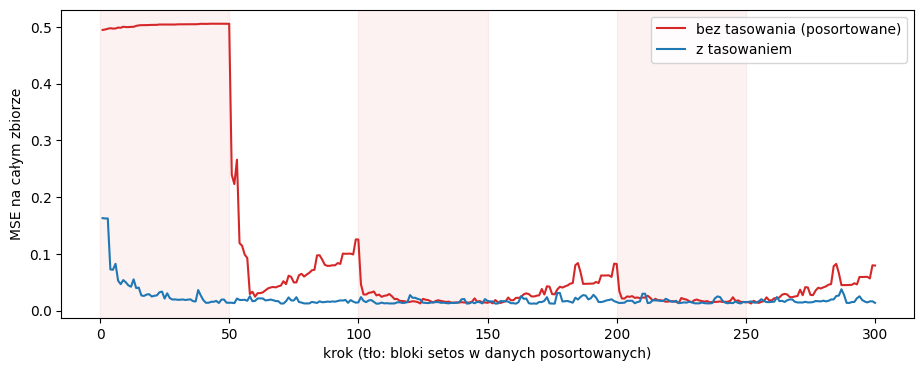

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
for shuffle, kolor, etykieta in [(False, "tab:red", "bez tasowania (posortowane)"), (True, "tab:blue", "z tasowaniem")]:
    m = AdalineMB(eta=0.1, n_iter=3, batch_size=1, shuffle=shuffle, zapisuj_kroki=True).fit(X_std, y)
    ax.plot(range(1, len(m.losses_kroki_) + 1), m.losses_kroki_, color=kolor, label=etykieta)
    print(f"{etykieta:<28} MSE po ostatniej epoce: {m.losses_[-1]:.3f}")
for k in range(3):
    ax.axvspan(k * 100, k * 100 + 50, color="tab:red", alpha=0.06)
ax.set_xlabel("krok (tło: bloki setos w danych posortowanych)"); ax.set_ylabel("MSE na całym zbiorze")
ax.legend(); plt.show()

**Pytanie 3.** Co się dzieje w pierwszych 50 krokach bez tasowania i dlaczego? Co widać w kolejnych epokach? Gdzie widzieliśmy już tę pułapkę?

✍️ **Twoja odpowiedź:**

W pierwszych 50 krokach bez tasowania model widzi wyłącznie kwiaty klasy 0, więc uczy się przewidywać same zera. W rezultacie MSE dla klasy 0 spada, ale na całym zbiorze (który zawiera też 50 przykładów klasy 1) błąd rośnie. W kolejnych 50 krokach widzi wyłącznie klasę 1 (versicolor) i zapomina poprzednią klasę.

W kolejnych epokach sytuacja się powtarza — widać wyraźne, że MSE zaczyna rosnąć a potem gwałtowanie spadać co 50 kroków.


# Część 3: mini-batch

## 3a. Słownictwo

| pojęcie | znaczenie |
|---|---|
| **batch** | porcja przykładów, z której liczymy jeden krok (rozmiar $B$) |
| **krok** (iteracja) | jedna aktualizacja wag |
| **epoka** | przejście przez cały zbiór, czyli $\lceil n/B \rceil$ kroków |

W Kerasie, którego użyjemy później: `model.fit(X, y, batch_size=32, epochs=20)`.

**Pytanie 4.** Breast Cancer ma $n = 569$. Policz **ręcznie**, ile kroków na epokę wykona model przy $B = 1$, $B = 32$, $B = 128$ i $B = 569$, i ile przykładów będzie w ostatnim batchu przy $B = 32$. Potem sprawdź w komórce poniżej.

✍️ **Twoja odpowiedź:**

B = 1: 569/1 = 569 kroków

B = 32: 569/32 = 17.78, 18 kroków

B = 128: 569/128 = 4.46, 5 kroków

B = 569: 569/569 = 1 krok

In [11]:
for Bs in [1, 32, 128, 569]:
    m = AdalineMB(eta=0.01, n_iter=1, batch_size=Bs).fit(Xb_std, yb)
    print(f"B = {Bs:<4} kroków na epokę: {m.n_krokow_}")

B = 1    kroków na epokę: 569
B = 32   kroków na epokę: 18
B = 128  kroków na epokę: 5
B = 569  kroków na epokę: 1


## 3b. Szum gradientu

Gradient z batcha to tylko **oszacowanie** gradientu z całego zbioru. Jak dokładne?

Funkcja `gradient` liczy $\partial L / \partial \mathbf{w}$ dla podanych przykładów. Ustalamy jakieś wagi `w0` i liczymy gradient z całego zbioru (`g_pelny`) oraz z wielu losowych batchy.

### Zadanie 5
Dla $B \in \{1,\ 8,\ 32,\ 128\}$ wylosuj 2000 batchy (`rng.choice(n, B, replace=False)`), policz dla każdego gradient i wypisz **rozrzut**: średnią odległość gradientu z batcha od `g_pelny`, podzieloną przez długość `g_pelny`:

$$\text{rozrzut} = \frac{\sqrt{\text{średnia}\ \lVert \mathbf{g}_B - \mathbf{g}_{\text{pełny}} \rVert^2}}{\lVert \mathbf{g}_{\text{pełny}} \rVert}$$

**Przewiduję:** ile razy zmaleje rozrzut, gdy batch będzie 4 razy większy?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**

Rozrzut maleje odwrotnie proporcjonalnie do pierwiastka z rozmiaru batcha, więc gdy batch będzie 4 razy większy, rozrzut powinien zmaleć około 2 razy.

In [12]:
def gradient(Xd, yd, w, b):
    # gradient MSE po wagach dla przykładów (Xd, yd)
    return -2.0 * Xd.T @ (yd - (Xd @ w + b)) / len(yd)

rng = np.random.RandomState(0)
w0 = rng.normal(0, 0.1, Xb_std.shape[1])          # jakieś ustalone wagi
g_pelny = gradient(Xb_std, yb, w0, 0.0)
n = len(yb)

In [13]:
for Bs in [1, 8, 32, 128]:
    grads = np.array([
        gradient(Xb_std[idx], yb[idx], w0, 0.0)
        for idx in (rng.choice(n, Bs, replace=False) for _ in range(2000))
    ])
    rozrzut = np.sqrt(((grads - g_pelny) ** 2).sum(axis=1).mean()) / np.linalg.norm(g_pelny)
    print(f"B = {Bs:<4} rozrzut: {rozrzut:.4f}")

B = 1    rozrzut: 1.9649
B = 8    rozrzut: 0.6799
B = 32   rozrzut: 0.3341
B = 128  rozrzut: 0.1489


Breast Cancer ma 30 wag, więc nie da się tego narysować. Na Iris (2 wagi) chmura gradientów z batchy wygląda tak:

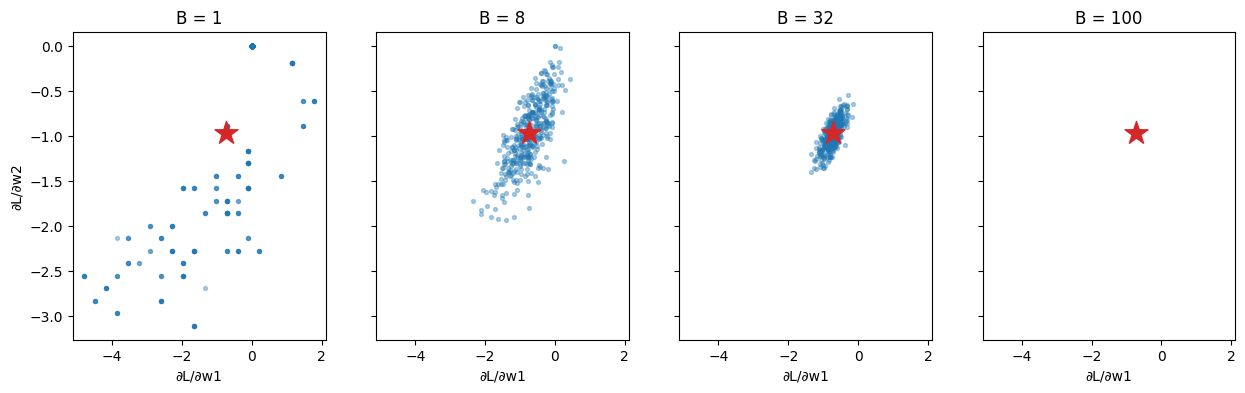

In [14]:
rng2 = np.random.RandomState(0)
g_iris = gradient(X_std, y, np.zeros(2), 0.0)
fig, axs = plt.subplots(1, 4, figsize=(15, 4), sharex=True, sharey=True)
for ax, Bs in zip(axs, [1, 8, 32, 100]):
    G = np.array([gradient(X_std[i], y[i], np.zeros(2), 0.0) for i in (rng2.choice(100, Bs, replace=False) for _ in range(400))])
    ax.scatter(G[:, 0], G[:, 1], s=8, alpha=0.35)
    ax.scatter(*g_iris, marker="*", s=300, color="tab:red", zorder=3)
    ax.set_title(f"B = {Bs}"); ax.set_xlabel("∂L/∂w1")
axs[0].set_ylabel("∂L/∂w2"); plt.show()

**Pytanie 5.** (a) Czy gradient z batcha „celuje” średnio w dobrą stronę? (b) Jak maleje rozrzut ze wzrostem $B$? Sprawdź: ile razy zmalał przy przejściu $B = 8 \to 32$, a ile przy $32 \to 128$? (c) Co to oznacza dla jednego kroku uczenia przy $B = 1$?

✍️ **Twoja odpowiedź:**

(a) Tak, gradient batcha średnio celuje w dobrą stronę.

(b) B = 8 -> B = 32: 2 razy (32/8 = 4, pierwiastek z 4 = 2)
B = 32 -> B = 128: 2 razy (128/32 = 4)

(c) Przy B = 1 szum jest bardzo duży - pojedynczy krok często kieruje wagi w stronę niemal losową

## 3c. $\eta$ i $B$ dobiera się razem

### Zadanie 6
Ucz `AdalineMB` na `Xb_std` przez 20 epok dla $B \in \{1,\ 8,\ 32,\ 569\}$ i $\eta \in \{0.001,\ 0.01,\ 0.05\}$. Wypisz tabelę trafności (wiersze: $B$, kolumny: $\eta$). Jeśli MSE po ostatniej epoce jest większe niż 1 albo nieskończone, wpisz „rozb.”.

**Przewiduję:** dla $B = 1$ najlepsze będzie małe czy duże $\eta$? A dla $B = 569$?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** ...

In [15]:
print("B       " + "".join(f"{f'η = {eta}':>12}" for eta in [0.001, 0.01, 0.05]))
with np.errstate(over="ignore", invalid="ignore"):
    for Bs in [1, 8, 32, 569]:
        wiersz = f"{Bs:<8}"
        for eta in [0.001, 0.01, 0.05]:
            m = AdalineMB(eta=eta, n_iter=20, batch_size=Bs).fit(Xb_std, yb)
            if not np.isfinite(m.losses_[-1]) or m.losses_[-1] > 1:
                wiersz += f"{'rozb.':>12}"
            else:
                traf = (m.predict(Xb_std) == yb).mean()
                wiersz += f"{traf:>12.0%}"
        print(wiersz)

B          η = 0.001    η = 0.01    η = 0.05
1                96%         78%       rozb.
8                97%         96%       rozb.
32               81%         96%         96%
569              37%         62%         97%


**Pytanie 6.** Gdzie w tabeli leżą najlepsze wyniki? Dlaczego mały batch potrzebuje małego $\eta$, a duży znosi duże? Dlaczego pełny GD ($B = 569$) przy $\eta = 0.001$ jest tak słaby?

✍️ **Twoja odpowiedź:**

Najlepsze wyniki leżą wzdłuż przekątnej tabeli (duże B i η lub małe B i η)

Mały batch generuje bardzo zaszumiony gradient - duże η powoduje, że pojedyncze zaszumione kroki wybijają wagi z minimum i prowadzą do rozbieżności. Duży batch uśrednia szum. Pełny GD B = 569 wykonuje tylko 1 krok na epokę, więc w ciągu 20 epok zrobił zaledwie 20 małych kroczków o długości η = 0.001 - to zdecydowanie za mało, aby zbliżyć się do minimum.

## 3d. Czas: dlaczego nie SGD?

Mierzymy czas **jednej epoki** na dużym, sztucznym zbiorze (100 000 przykładów, 20 cech).

**Przewiduję:** który $B$ będzie najwolniejszy, a który najszybszy?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**

Najwolniejszy będzie B = 1, ponieważ wymaga wykonania 100 000 iteracji pętli. Najszybsze będą największe wartości, ponieważ zmniejsza się liczba kroków/iteracji.

In [16]:
rs = np.random.RandomState(0)
X_duzy = rs.randn(100_000, 20)
y_duzy = (X_duzy @ rs.randn(20) > 0).astype(float)

for Bs in [1, 32, 256, len(y_duzy)]:
    t0 = time.perf_counter()
    m = AdalineMB(eta=0.001, n_iter=1, batch_size=Bs).fit(X_duzy, y_duzy)
    print(f"B = {Bs:<7} kroków: {m.n_krokow_:<7} czas epoki: {time.perf_counter() - t0:.3f} s")

B = 1       kroków: 100000  czas epoki: 2.158 s
B = 32      kroków: 3125    czas epoki: 0.136 s
B = 256     kroków: 391     czas epoki: 0.034 s
B = 100000  kroków: 1       czas epoki: 0.031 s


**Pytanie 7.** Dlaczego SGD jest kilkadziesiąt razy wolniejszy, choć liczy dokładnie tyle samo iloczynów (każdy przykład raz na epokę)? Dlaczego w praktyce używa się $B$ rzędu 32–256, a nie pełnego GD, skoro ten jest równie szybki na epokę?

✍️ **Twoja odpowiedź:**
Python wykonuje pętlę i wywołuje operacje NumPy 100 000 razy na epokę. Sprawia to, że obliczenia są dziesiątki razy wolniejsze niż jedno duże mnożenie macierzy.

Pełny GD robi tylko jeden krok na całą epokę, więc model uczy się bardzo wolno. Mini-batch jest niemal tak samo szybki w obliczeniach, ale w jednej epoce poprawia wagi setki razy, więc model dochodzi do dobrego wyniku znacznie szybciej.

## 3e. Epoki czy kroki?

Porównujemy krzywe straty dla każdego $B$ z dobrym $\eta$ (z tabeli w 3c) na dwóch osiach: **epokach** (ile razy przejrzeliśmy dane) i **krokach** (ile razy zmieniliśmy wagi).

B = 1    η = 0.001  MSE po 1. epoce = 0.111, po 20. = 0.056, kroków = 11380
B = 8    η = 0.01   MSE po 1. epoce = 0.087, po 20. = 0.062, kroków = 1440
B = 32   η = 0.05   MSE po 1. epoce = 0.138, po 20. = 0.059, kroków = 360
B = 569  η = 0.07   MSE po 1. epoce = 0.465, po 20. = 0.064, kroków = 20


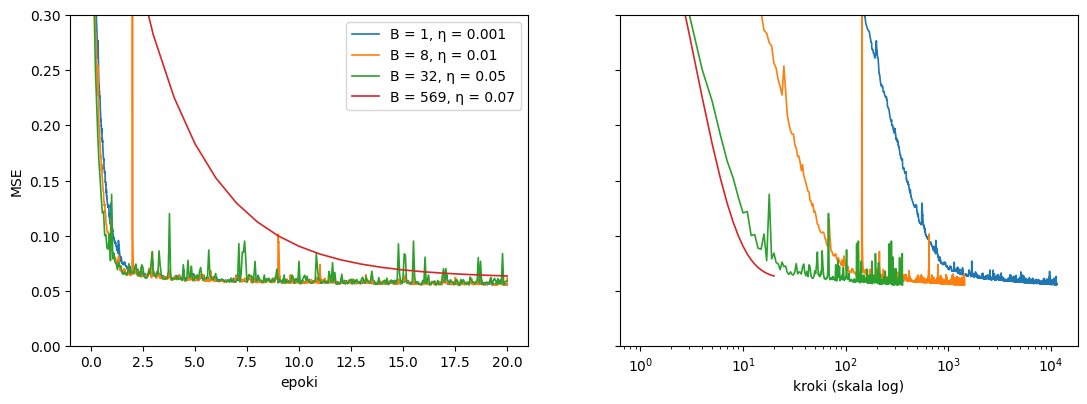

In [19]:
ustawienia = [(1, 0.001), (8, 0.01), (32, 0.05), (569, 0.07)]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for Bs, eta in ustawienia:
    m = AdalineMB(eta=eta, n_iter=20, batch_size=Bs, zapisuj_kroki=True).fit(Xb_std, yb)
    kroki = np.arange(1, len(m.losses_kroki_) + 1)
    axs[0].plot(kroki / np.ceil(len(yb) / Bs), m.losses_kroki_, lw=1.2, label=f"B = {Bs}, η = {eta}")
    axs[1].plot(kroki, m.losses_kroki_, lw=1.2)
    print(f"B = {Bs:<4} η = {eta:<6} MSE po 1. epoce = {m.losses_[0]:.3f}, po 20. = {m.losses_[-1]:.3f}, kroków = {m.n_krokow_}")
axs[0].set_xlabel("epoki"); axs[1].set_xlabel("kroki (skala log)"); axs[1].set_xscale("log")
axs[0].set_ylabel("MSE"); axs[0].set_ylim(0, 0.3); axs[0].legend(); plt.show()

**Pytanie 8.** Który $B$ „wygrywa” na osi epok, a który na osi kroków? Który byś wybrał w praktyce i dlaczego? Skąd biorą się szpilki na krzywych małych batchy?

✍️ **Twoja odpowiedź:**

Na osi epok wygrywają małe batche, ponieważ najszybciej spadają do niskiego błędu.
Na osi kroków wygrywa duży batch, ponieważ osiąga najniższy błąd w zaledwie 20 krokach, podczas gdy inne, mniejsze batche potrzebują dużo więcej kroków.

Najlepiej wybrać B = 32. Zbiega niemal tak samo szybko w przeliczeniu na epoki jak B = 1 czy B = 8, ale wykonuje wielokrotnie mniej kroków, dzięki czemu obliczenia są bardzo szybkie.

Szpilki na krzywych małych batchy pojawiają się wtedy, gdy do małego batcha trafi jeden lub kilka nietypowych, trudnych przykładów. Ponieważ batch jest mały, ich pojedynczy, bardzo duży błąd nie zostaje uśredniony przez resztę zbioru, co powoduje nagły, silny ruch wag w złą stronę i chwilowy skok MSE.

## 4. Podsumowanie

Odpowiedz krótko własnymi słowami (kliknij dwukrotnie, żeby edytować):

1. Dlaczego standaryzacja poszerza zakres dobrych $\eta$?

Bo wszystkie cechy mają podobną skalę i jedna wartość współczynnika uczenia pasuje do każdej wagi.

2. Po co tasujemy dane przed każdą epoką?

Żeby kolejność przykładów w zbiorze (np. pogrupowane klasy) nie psuła uczenia i nie powodowała ciągłego przełączania się wag.

3. Czym są SGD i pełny spadek gradientu w rodzinie mini-batch?

SGD to mini-batch o rozmiarze 1, a pełny spadek gradientu to mini-batch o rozmiarze całego zbioru.

4. Jak szum gradientu zależy od $B$?

Szum maleje wraz ze wzrostem rozmiaru batcha (dokładniej: odwrotnie proporcjonalnie do pierwiastka z rozmiaru batcha).

5. Dlaczego w praktyce używa się mini-batchy, a nie SGD ani pełnego GD?

Bo łączy szybkość obliczeń macierzowych z częstymi aktualizacjami wag w obrębie jednej epoki.

6. Co trzeba zrobić z $\eta$, gdy zmienia się `batch_size`?

Dostosować je do rozmiaru batcha — przy mniejszym batchu zwykle zmniejszyć, a przy większym można zwiększyć.


---
## Zadanie dodatkowe (na ocenę 4/5): standaryzacja a dane testowe

1. Podziel Breast Cancer na zbiór treningowy i testowy: `from sklearn.model_selection import train_test_split`, `test_size=0.3`, `random_state=1`, `stratify=yb`.
2. Policz $\mu$ i $\sigma$ **tylko na treningowym**, przekształć nimi oba zbiory.
3. Ucz `AdalineMB` ($B = 32$, $\eta = 0.01$, 20 epok) na treningowym; podaj trafność na treningowym i testowym.
4. Dlaczego nie wolno liczyć $\mu$, $\sigma$ na całym zbiorze ani osobno na testowym?

In [ ]:
# Zadanie dodatkowe — Twój kod